# K-Means from Scratch

K-Means clustering implemented with NumPy: centroid initialization, assignment and update steps, with visualization.

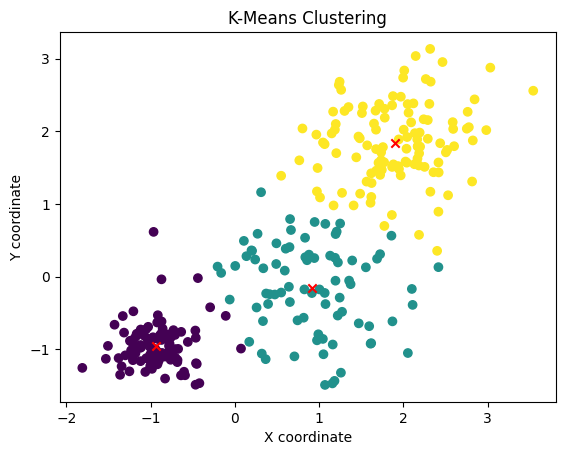

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Euclidean distance
def euclidean_distance(a, b):
    return np.sqrt(np.sum((a - b) ** 2))


def initialize_centroids(X, k):
    indices = np.random.choice(X.shape[0], k, replace=False)
    return X[indices]

def assign_clusters(X, centroids):
    clusters = []
    for x in X:
        distances = [euclidean_distance(x, centroid) for centroid in centroids]
        cluster = np.argmin(distances)
        clusters.append(cluster)
    return np.array(clusters)

def update_centroids(X, clusters, k):
    new_centroids = []
    for i in range(k):
        cluster_points = X[clusters == i]
        new_centroid = np.mean(cluster_points, axis=0)
        new_centroids.append(new_centroid)
    return np.array(new_centroids)

# K-Means algorithm
def kmeans(X, k, max_iters=100):
    centroids = initialize_centroids(X, k)
    for _ in range(max_iters):
        clusters = assign_clusters(X, centroids)
        new_centroids = update_centroids(X, clusters, k)
        if np.all(centroids == new_centroids):
            break
        centroids = new_centroids
    return centroids, clusters

# Creating a dataset
np.random.seed(42)
X = np.vstack((np.random.randn(100, 2) * 0.75 + np.array([1, 0]),
               np.random.randn(100, 2) * 0.25 + np.array([-1, -1]),
               np.random.randn(100, 2) * 0.5 + np.array([2, 2])))

k = 3

centroids, clusters = kmeans(X, k)

plt.scatter(X[:, 0], X[:, 1], c=clusters, cmap='viridis', marker='o')
plt.scatter(centroids[:, 0], centroids[:, 1], c='red', marker='x')
plt.title('K-Means Clustering')
plt.xlabel('X coordinate')
plt.ylabel('Y coordinate')
plt.show()